# SilverAI - Notebook 09: Scenario Analysis

Generate retrospective bullish, bearish, and neutral scenario summaries from the validation-selected models. This is descriptive historical analysis, not a trading or profitability claim. Probabilities are kept separate from calibrated confidence.

In [1]:
from pathlib import Path
import json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
PROJECT_ROOT=Path.cwd()
if not (PROJECT_ROOT/'data').exists(): PROJECT_ROOT=Path('..').resolve()
INPUT_PATH=PROJECT_ROOT/'data'/'silver_modeling_data.csv'; MODEL_ROOT=PROJECT_ROOT/'saved_models'
REPORT_ROOT=PROJECT_ROOT/'reports'/'model_comparison'; FIGURE_ROOT=PROJECT_ROOT/'reports'/'figures'
FEATURE_COLUMNS=['return_1','return_3','return_6','volatility_5','volatility_20','volatility_50','sma_distance_20','sma_distance_50','candle_return','candle_range_pct','upper_wick_ratio','lower_wick_ratio','relative_volume','volume_change','hour_sin','hour_cos','day_of_week']
REGRESSION_TARGET='future_return_15m'; SAVED_CLASSIFICATION_TARGET='target_direction_15m'; PURGE_ROWS=3
selection=json.loads((REPORT_ROOT/'evaluation_selection.json').read_text(encoding='utf-8')); classifier_name=selection['selected_classifier']; regressor_name=selection['selected_regressor']
metadata=json.loads((MODEL_ROOT/'metadata'/'training_metadata.json').read_text(encoding='utf-8')); assert metadata['feature_names']==FEATURE_COLUMNS
threshold=float(metadata['threshold_value_pct']); classifier=joblib.load(MODEL_ROOT/'classifier'/f'{classifier_name}.joblib'); regressor=joblib.load(MODEL_ROOT/'regressor'/f'{regressor_name}.joblib')

C:\Users\ravik\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator LabelEncoder from version 1.7.2 when using version 1.7.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\ravik\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator _BinMapper from version 1.7.2 when using version 1.7.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\ravik\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator His

In [2]:
df=pd.read_csv(INPUT_PATH); df['_sort']=pd.to_datetime(df.datetime_et,errors='coerce',utc=True); df=df.sort_values('_sort',kind='mergesort').reset_index(drop=True)
numeric=FEATURE_COLUMNS+[REGRESSION_TARGET]; invalid=df[FEATURE_COLUMNS].isna().any(axis=1)|df[[REGRESSION_TARGET,SAVED_CLASSIFICATION_TARGET]].isna().any(axis=1)|np.isinf(df[numeric].to_numpy(float)).any(axis=1); clean=df.loc[~invalid].reset_index(drop=True).copy()
n=len(clean); b70=int(n*.70); b85=int(n*.85); train_raw=clean.iloc[:b70].copy(); validation_raw=clean.iloc[b70:b85].copy(); test=clean.iloc[b85:].copy(); train=train_raw.iloc[:-PURGE_ROWS].copy(); validation=validation_raw.iloc[:-PURGE_ROWS].copy()
def labels(s): return pd.Series(np.where(s>threshold,1,np.where(s<-threshold,-1,0)),index=s.index,dtype='int64')
validation['eval_direction']=labels(validation[REGRESSION_TARGET]); test['eval_direction']=labels(test[REGRESSION_TARGET])
X_val=validation[FEATURE_COLUMNS]; X_test=test[FEATURE_COLUMNS]; val_pred=classifier.predict(X_val); test_pred=classifier.predict(X_test); test_proba=classifier.predict_proba(X_test)
classes=list(classifier.classes_); class_index={int(c):i for i,c in enumerate(classes)}; val_report=pd.DataFrame(classification_report(validation.eval_direction,val_pred,labels=[-1,0,1],target_names=['DOWN','NEUTRAL','UP'],output_dict=True,zero_division=0)).T
precision_reference={-1:float(val_report.loc['DOWN','precision']),0:float(val_report.loc['NEUTRAL','precision']),1:float(val_report.loc['UP','precision'])}; reg_pred=regressor.predict(X_test)
print('Scenario rows:',len(test),'validation precision reference:',precision_reference)

C:\Users\ravik\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\ravik\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "C:\Users\ravik\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\ravik\AppData\Local\Programs\Python\Pytho

Scenario rows: 24086 validation precision reference: {-1: 0.40128389886021226, 0: 0.38297161936560936, 1: 0.44407283537718323}


In [3]:
name_map={-1:'Bearish',0:'Neutral',1:'Bullish'}
result=pd.DataFrame({'datetime_et':test.datetime_et.to_numpy(),'predicted_direction':test_pred,'predicted_15m_return':reg_pred,'actual_future_return_15m':test[REGRESSION_TARGET].to_numpy(),'actual_direction':test.eval_direction.to_numpy(),'volatility_20':test.volatility_20.to_numpy(),'relative_volume':test.relative_volume.to_numpy()})
for c in (-1,0,1): result[f'probability_{name_map[c].lower()}']=test_proba[:,class_index[c]]
result['predicted_direction_name']=result.predicted_direction.map(name_map); result['max_class_probability']=test_proba.max(axis=1); result['predicted_class_probability']=[test_proba[i,class_index[int(c)]] for i,c in enumerate(test_pred)]
result['validation_precision_reference']=[precision_reference[int(c)] for c in test_pred]; result['confidence_status']='Not calibrated; probability and validation precision reference only'
result['regression_implied_direction']=np.where(result.predicted_15m_return>threshold,1,np.where(result.predicted_15m_return<-threshold,-1,0)); result['classification_regression_agreement']=result.predicted_direction==result.regression_implied_direction
result['scenario']=result.predicted_direction_name; result.to_csv(REPORT_ROOT/'scenario_analysis_results.csv',index=False)
display(result.head())

,datetime_et,predicted_direction,predicted_15m_return,actual_future_return_15m,actual_direction,volatility_20,relative_volume,probability_bearish,probability_neutral,probability_bullish,predicted_direction_name,max_class_probability,predicted_class_probability,validation_precision_reference,confidence_status,regression_implied_direction,classification_regression_agreement,scenario
0,2026-05-06 08:35:00-04:00,1,-0.007492,-0.090509,-1,0.289604,0.805006,0.375445,0.200360,0.424195,Bullish,0.424195,0.424195,0.444073,Not calibrated; probability and validation pre...,0,False,Bullish
1,2026-05-06 08:40:00-04:00,1,-0.003054,0.129433,1,0.286798,0.655450,0.389668,0.186346,0.423986,Bullish,0.423986,0.423986,0.444073,Not calibrated; probability and validation pre...,0,False,Bullish
2,2026-05-06 08:45:00-04:00,1,0.016013,0.064637,0,0.277730,0.588029,0.380189,0.185504,0.434307,Bullish,0.434307,0.434307,0.444073,Not calibrated; probability and validation pre...,0,False,Bullish
3,2026-05-06 08:50:00-04:00,1,0.005226,-0.213537,-1,0.277983,0.467651,0.384118,0.179754,0.436128,Bullish,0.436128,0.436128,0.444073,Not calibrated; probability and validation pre...,0,False,Bullish
4,2026-05-06 08:55:00-04:00,1,0.010988,0.058170,0,0.279430,0.536654,0.372334,0.204532,0.423134,Bullish,0.423134,0.423134,0.444073,Not calibrated; probability and validation pre...,0,False,Bullish


In [4]:
frequency=result.groupby(['scenario'],as_index=False).agg(rows=('scenario','size'),percentage=('scenario',lambda s:100*len(s)/len(result)),mean_predicted_return=('predicted_15m_return','mean'),mean_actual_return=('actual_future_return_15m','mean'),agreement_rate=('classification_regression_agreement','mean'))
accuracy=result.assign(correct=result.predicted_direction==result.actual_direction).groupby('scenario',as_index=False).agg(rows=('correct','size'),direction_accuracy=('correct','mean'),mean_actual_return=('actual_future_return_15m','mean'),mean_volatility_20=('volatility_20','mean'),mean_relative_volume=('relative_volume','mean'))
disagreement=result.groupby('classification_regression_agreement',as_index=False).agg(rows=('classification_regression_agreement','size'),mean_actual_return=('actual_future_return_15m','mean'),direction_accuracy=('actual_direction',lambda s:np.nan))
frequency.to_csv(REPORT_ROOT/'scenario_frequency_summary.csv',index=False); accuracy.to_csv(REPORT_ROOT/'scenario_accuracy_summary.csv',index=False); result.groupby('predicted_direction_name').size().rename('rows').to_csv(REPORT_ROOT/'scenario_direction_counts.csv')
val_report.to_csv(REPORT_ROOT/'scenario_validation_precision_reference.csv'); display(frequency.round(4)); display(accuracy.round(4))

,scenario,rows,percentage,mean_predicted_return,mean_actual_return,agreement_rate
0,Bearish,5171,21.4689,0.0036,-0.0091,0.0000
1,Bullish,12433,51.6192,0.0027,-0.0004,0.0001
2,Neutral,6482,26.9119,0.0013,-0.0040,1.0000


,scenario,rows,direction_accuracy,mean_actual_return,mean_volatility_20,mean_relative_volume
0,Bearish,5171,0.4148,-0.0091,0.2072,1.3417
1,Bullish,12433,0.3780,-0.0004,0.1860,1.1769
2,Neutral,6482,0.3699,-0.0040,0.1102,0.8032


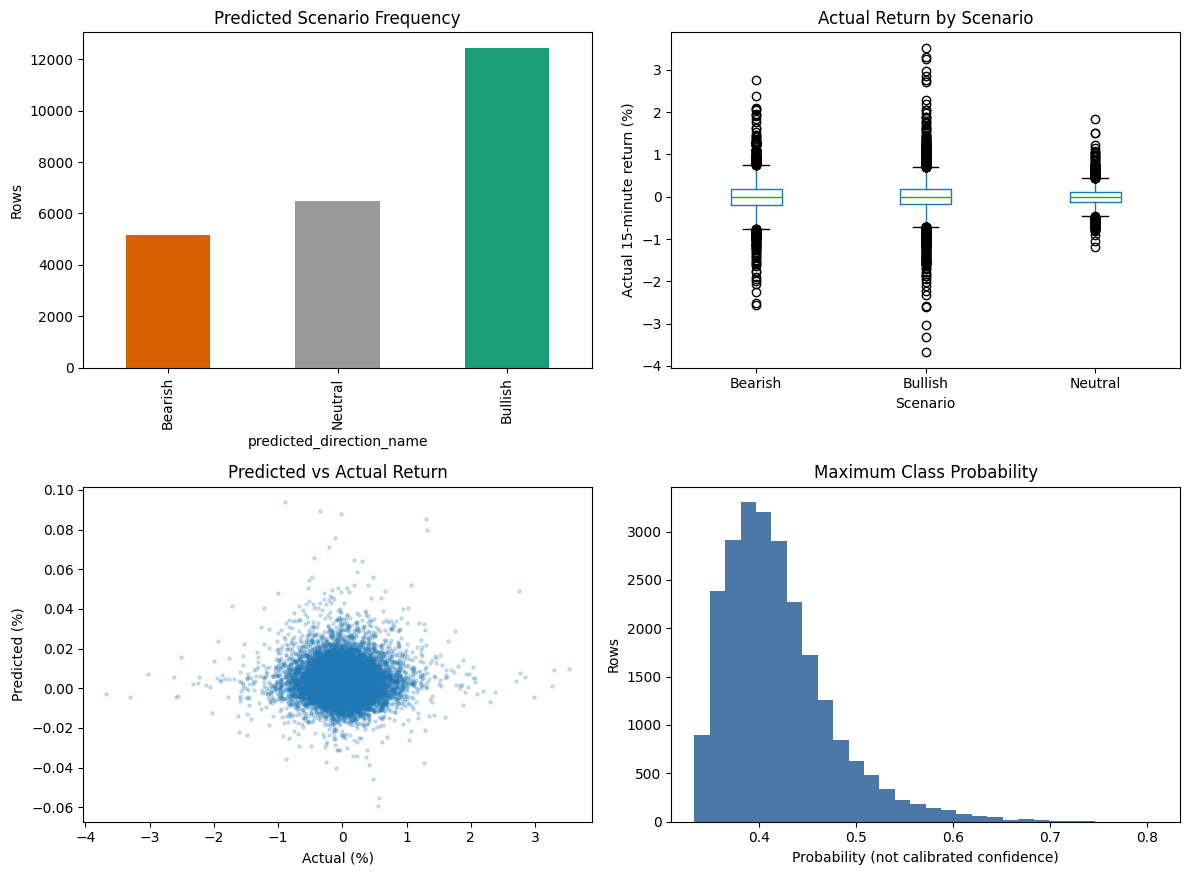

Saved scenario results and summaries to C:\Users\ravik\Desktop\SilverAI\reports\model_comparison
No calibrated confidence or trading claim is produced.


In [5]:
fig,axes=plt.subplots(2,2,figsize=(12,9)); result.predicted_direction_name.value_counts().reindex(['Bearish','Neutral','Bullish']).plot.bar(ax=axes[0,0],color=['#d95f02','#999999','#1b9e77']); axes[0,0].set_title('Predicted Scenario Frequency'); axes[0,0].set_ylabel('Rows')
result.boxplot(column='actual_future_return_15m',by='scenario',ax=axes[0,1],grid=False); axes[0,1].set_title('Actual Return by Scenario'); axes[0,1].set_xlabel('Scenario'); axes[0,1].set_ylabel('Actual 15-minute return (%)'); plt.suptitle('')
axes[1,0].scatter(result.actual_future_return_15m,result.predicted_15m_return,s=5,alpha=.2); axes[1,0].set_title('Predicted vs Actual Return'); axes[1,0].set_xlabel('Actual (%)'); axes[1,0].set_ylabel('Predicted (%)')
axes[1,1].hist(result.max_class_probability,bins=30,color='#4c78a8'); axes[1,1].set_title('Maximum Class Probability'); axes[1,1].set_xlabel('Probability (not calibrated confidence)'); axes[1,1].set_ylabel('Rows'); fig.tight_layout(); fig.savefig(FIGURE_ROOT/'14_scenario_analysis_overview.png',dpi=160); plt.show()
print('Saved scenario results and summaries to',REPORT_ROOT); print('No calibrated confidence or trading claim is produced.')